In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Load the dataset (fixed the double .parquet typo)
df = pd.read_parquet('../data/network_intrusion_clustering.parquet')

# 2. Drop Label — clustering is unsupervised, Label used only for evaluation
# Notice we are using 'df' here, not 'df_clustering'
X = df.drop(columns=['Label'])
y = df['Label']  # saved for post-hoc interpretation

# 3. Standardize features (zero mean, unit variance)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Feature matrix shape : {X_scaled.shape}")
print(f"Label series shape   : {y.shape}")
print("All scaled with standart scaler ")

Feature matrix shape : (20206, 25)
Label series shape   : (20206,)
All scaled with standart scaler 


In [2]:
import json

# 1. Load the label mapping JSON file
# (Make sure the path matches your folder structure)
with open('../data/label_mapping.json', 'r') as f:
    label_mapping = json.load(f)

# 2. Reverse the dictionary so numbers are the keys
# JSON saves keys as strings, so we convert the value 'v' to an integer
inverse_mapping = {int(v): k for k, v in label_mapping.items()}

# 3. Create a permanent 'Label_Name' column for easy evaluation later
df['Label_Name'] = df['Label'].map(inverse_mapping)

print("Label mapping loaded!")

Label mapping loaded!


## K-Means

k= 2 | Inertia:     425190.8 | Silhouette: 0.5174 | Davies-Bouldin: 1.6643
k= 3 | Inertia:     387101.1 | Silhouette: 0.5051 | Davies-Bouldin: 1.3834
k= 4 | Inertia:     359830.9 | Silhouette: 0.4903 | Davies-Bouldin: 1.3774
k= 5 | Inertia:     326754.8 | Silhouette: 0.4332 | Davies-Bouldin: 1.4219
k= 6 | Inertia:     312265.2 | Silhouette: 0.4662 | Davies-Bouldin: 1.1617
k= 7 | Inertia:     284007.3 | Silhouette: 0.4547 | Davies-Bouldin: 1.2459
k= 8 | Inertia:     262628.1 | Silhouette: 0.4277 | Davies-Bouldin: 1.0294
k= 9 | Inertia:     243735.6 | Silhouette: 0.4681 | Davies-Bouldin: 1.0342
k=10 | Inertia:     223509.7 | Silhouette: 0.4948 | Davies-Bouldin: 0.9627
k=11 | Inertia:     209493.1 | Silhouette: 0.4433 | Davies-Bouldin: 1.0470


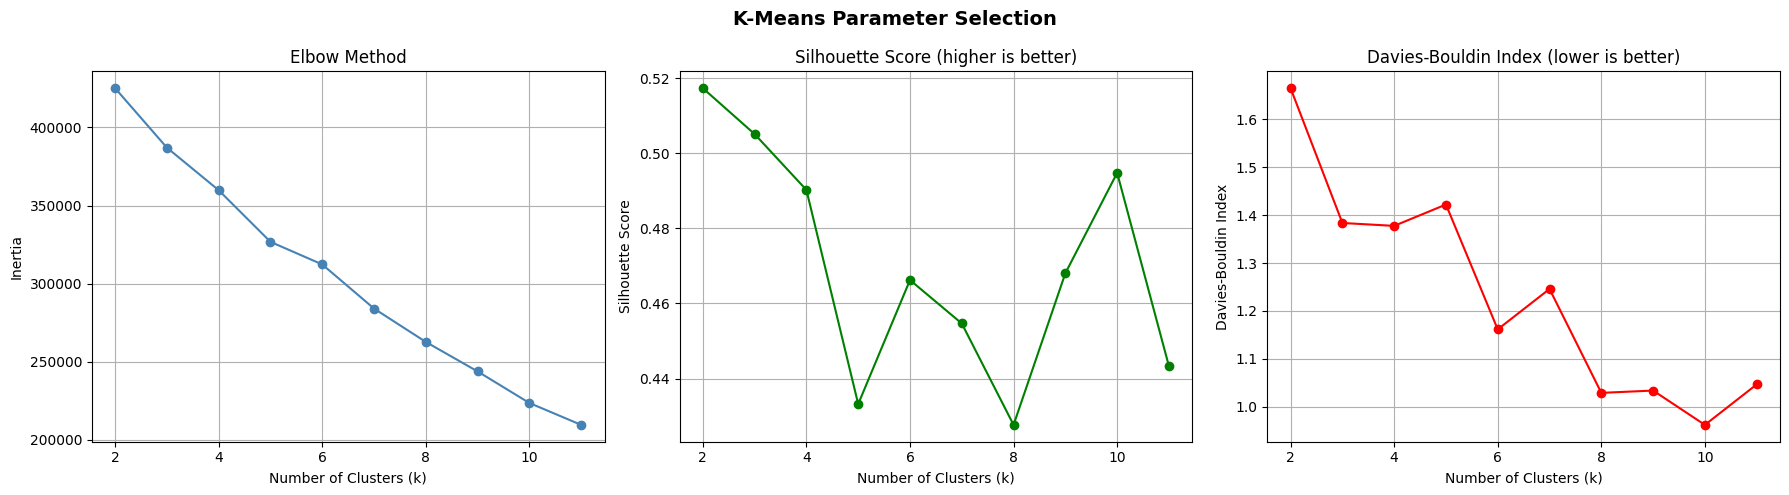


  Best k selected    : 2
   Silhouette Score  : 0.5174
   Davies-Bouldin    : 1.6643
   ARI               : 0.2443  (1.0 = perfect, 0 = random)
   NMI               : 0.1556  (1.0 = perfect, 0 = no mutual info)

 K-Means complete. Cluster labels saved to df.


In [4]:
# =============================================================
# K-MEANS CLUSTERING
# =============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score

k_range = range(2, 12)

inertias          = []
silhouette_scores = []
db_scores         = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)

    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))

    print(f"k={k:2d} | Inertia: {km.inertia_:>12.1f} | "
          f"Silhouette: {silhouette_scores[-1]:.4f} | "
          f"Davies-Bouldin: {db_scores[-1]:.4f}")

# -------------------------------------------------------------
# Plots
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(k_range, inertias, marker='o', color='steelblue')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].grid(True)

axes[1].plot(k_range, silhouette_scores, marker='o', color='green')
axes[1].set_title('Silhouette Score (higher is better)')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True)

axes[2].plot(k_range, db_scores, marker='o', color='red')
axes[2].set_title('Davies-Bouldin Index (lower is better)')
axes[2].set_xlabel('Number of Clusters (k)')
axes[2].set_ylabel('Davies-Bouldin Index')
axes[2].grid(True)

plt.suptitle('K-Means Parameter Selection', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# Best k & Final Model
# -------------------------------------------------------------
best_k = silhouette_scores.index(max(silhouette_scores)) + 2

km_best = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = km_best.fit_predict(X_scaled)

# Save labels back to df
df['KMeans_Cluster'] = kmeans_labels

# -------------------------------------------------------------
# Evaluation vs Ground Truth (Label)
# -------------------------------------------------------------
ari = adjusted_rand_score(y, kmeans_labels)
nmi = normalized_mutual_info_score(y, kmeans_labels)

print(f"\n  Best k selected    : {best_k}")
print(f"   Silhouette Score  : {max(silhouette_scores):.4f}")
print(f"   Davies-Bouldin    : {db_scores[best_k - 2]:.4f}")
print(f"   ARI               : {ari:.4f}  (1.0 = perfect, 0 = random)")
print(f"   NMI               : {nmi:.4f}  (1.0 = perfect, 0 = no mutual info)")

print("\n K-Means complete. Cluster labels saved to df.")

In [14]:
# Automated search selected k=2, driven by class imbalance (83% BENIGN).
# Overriding to k=10: lowest Davies-Bouldin (0.9627) + ~14 traffic categories in dataset.
best_k = 6
km_best = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = km_best.fit_predict(X_scaled)
df['KMeans_Cluster'] = kmeans_labels

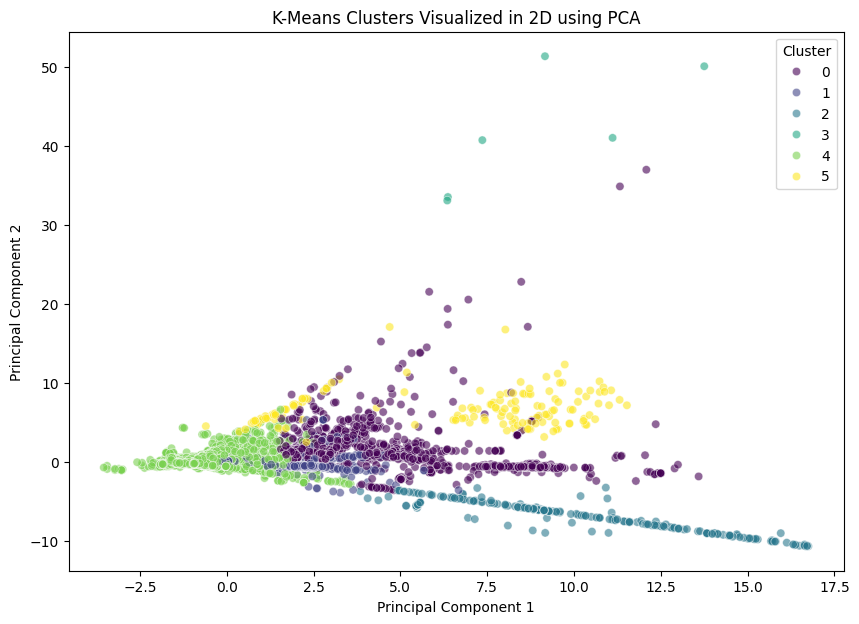

In [15]:
from sklearn.decomposition import PCA
import seaborn as sns

# Squash the 25 dimensions down to 2 dimensions (Principal Components)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot the PCA results, coloring the dots by their K-Means cluster
plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['KMeans_Cluster'], palette='viridis', alpha=0.6)
plt.title('K-Means Clusters Visualized in 2D using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

In [16]:
# Create a table comparing the true label names to the K-Means clusters
kmeans_analysis = pd.crosstab(
    index=df['Label_Name'], 
    columns=df['KMeans_Cluster'], 
    margins=True
)

print("K-Means Cluster Distribution vs. True Labels:")
display(kmeans_analysis)

K-Means Cluster Distribution vs. True Labels:


KMeans_Cluster,0,1,2,3,4,5,All
Label_Name,,,,,,,
BENIGN,1408,35,223,0,14915,158,16739
Bot,0,0,0,0,16,0,16
DDoS,0,351,0,0,673,0,1024
DoS GoldenEye,1,26,12,0,43,0,82
DoS Hulk,350,770,1,0,260,0,1381
DoS Slowhttptest,12,17,0,0,12,1,42
DoS slowloris,17,0,10,0,16,0,43
FTP-Patator,0,0,0,0,47,0,47
Heartbleed,6,1,0,0,0,0,7


## Hierarchical

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 2. Evaluate Linkages and k
k_range = range(2, 7)
linkages = ['ward', 'complete', 'average', 'single']

results = []

print("Evaluating Hierarchical Clustering...\n")
print(f"{'Linkage':<10} | {'k':<3} | {'Silhouette':<12} | {'Davies-Bouldin'}")
print("-" * 50)

# After the loop, before finding best_idx
# Add cluster balance check — compute smallest cluster size as % of data
def min_cluster_pct(X, labels):
    unique, counts = np.unique(labels, return_counts=True)
    return counts.min() / len(labels) * 100

for linkage in linkages:
    for k in k_range:
        # Ward requires euclidean distance; the others can use different metrics, 
        # but sticking to euclidean keeps the comparison standardized.
        hc = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage=linkage)
        labels = hc.fit_predict(X_scaled)
        
        # Calculate internal metrics
        sil_score = silhouette_score(X_scaled, labels)
        db_score = davies_bouldin_score(X_scaled, labels)
        min_pct   = min_cluster_pct(X_scaled, labels)
        
        results.append({
            'linkage': linkage,
            'k': k,
            'silhouette': sil_score,
            'davies_bouldin': db_score,
            'min_cluster_pct': min_pct 
        })
        
        print(f"{linkage:<10} | {k:<3} | {sil_score:<12.4f} | {db_score:.4f}")
    print("-" * 40)

# Convert to DataFrame for easy querying
results_df = pd.DataFrame(results)

Evaluating Hierarchical Clustering...

Linkage    | k   | Silhouette   | Davies-Bouldin
--------------------------------------------------
ward       | 2   | 0.5041       | 1.7373
ward       | 3   | 0.4981       | 1.4779
ward       | 4   | 0.4961       | 1.1567
ward       | 5   | 0.4886       | 1.0964
ward       | 6   | 0.4809       | 1.0095
----------------------------------------
complete   | 2   | 0.9394       | 0.2093
complete   | 3   | 0.9234       | 0.3945
complete   | 4   | 0.9182       | 0.3562
complete   | 5   | 0.7481       | 0.6760
complete   | 6   | 0.7233       | 0.5193
----------------------------------------
average    | 2   | 0.9394       | 0.2093
average    | 3   | 0.9234       | 0.3945
average    | 4   | 0.9182       | 0.3562
average    | 5   | 0.9182       | 0.3897
average    | 6   | 0.8529       | 0.3855
----------------------------------------
single     | 2   | 0.9394       | 0.2093
single     | 3   | 0.9241       | 0.2567
single     | 4   | 0.9181       | 0.2295


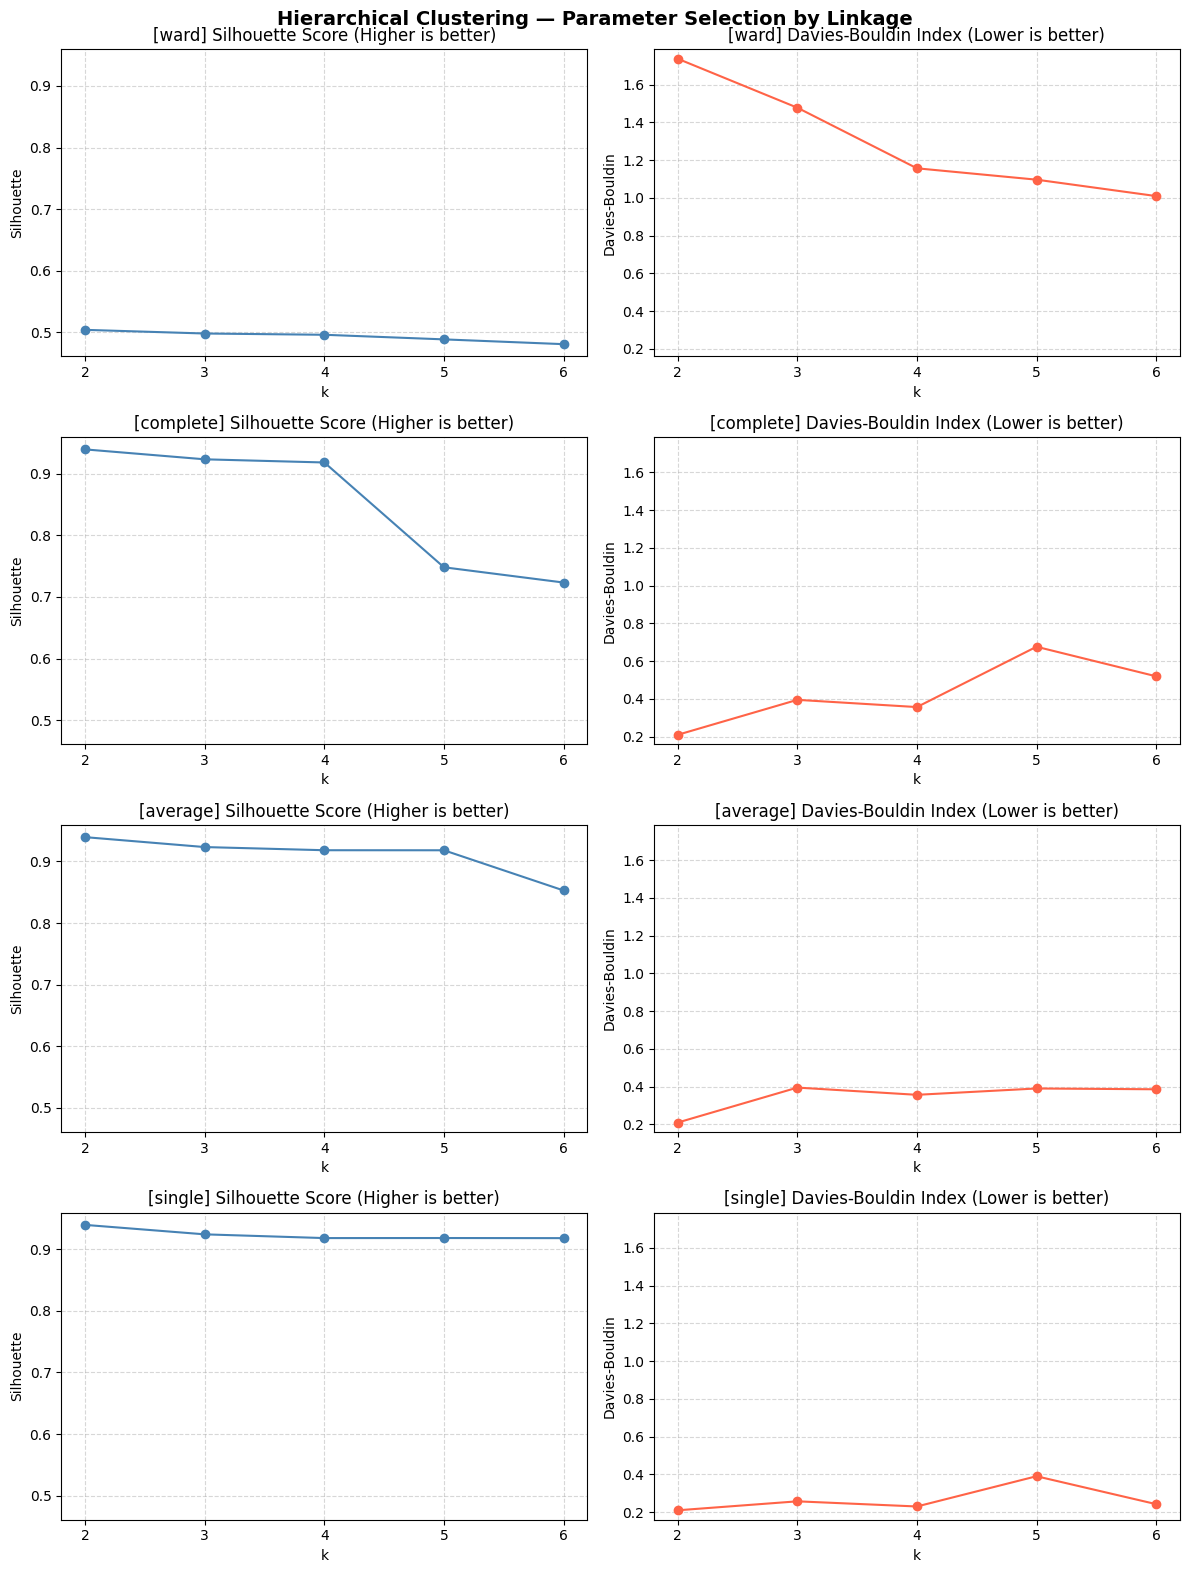

In [30]:
sil_min, sil_max = results_df['silhouette'].min(), results_df['silhouette'].max()
db_min,  db_max  = results_df['davies_bouldin'].min(), results_df['davies_bouldin'].max()

fig, axes = plt.subplots(len(linkages), 2, figsize=(12, 4 * len(linkages)))

for row, linkage in enumerate(linkages):
    df_link = results_df[results_df['linkage'] == linkage]
    
    axes[row, 0].plot(df_link['k'], df_link['silhouette'], marker='o', color='steelblue')
    axes[row, 0].set_title(f'[{linkage}] Silhouette Score (Higher is better)')
    axes[row, 0].set_xlabel('k')
    axes[row, 0].set_ylabel('Silhouette')
    axes[row, 0].set_xticks(df_link['k'])
    axes[row, 0].set_ylim(sil_min - 0.02, sil_max + 0.02)
    axes[row, 0].grid(True, linestyle='--', alpha=0.5)

    axes[row, 1].plot(df_link['k'], df_link['davies_bouldin'], marker='o', color='tomato')
    axes[row, 1].set_title(f'[{linkage}] Davies-Bouldin Index (Lower is better)')
    axes[row, 1].set_xlabel('k')
    axes[row, 1].set_ylabel('Davies-Bouldin')
    axes[row, 1].set_xticks(df_link['k'])
    axes[row, 1].set_ylim(db_min - 0.05, db_max + 0.05)
    axes[row, 1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Hierarchical Clustering — Parameter Selection by Linkage', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [31]:
# Only consider results where every cluster holds at least 5% of the data
valid_df = results_df[results_df['min_cluster_pct'] >= 5.0]

if valid_df.empty:
    print("No configuration met the min_cluster_pct >= 5% threshold (likely due to class imbalance). Falling back to all results.")
    valid_df = results_df

best_idx = valid_df['silhouette'].idxmax()

# -------------------------------------------------------------
# 3. Find Best Parameters & Save Final Model
# -------------------------------------------------------------

# Automatically find the parameters that yielded the highest Silhouette score
best_k = int(results_df.loc[best_idx, 'k'])
best_linkage = results_df.loc[best_idx, 'linkage']
best_silhouette = results_df.loc[best_idx, 'silhouette']

print("\n" + "=" * 40)
print("BEST MODEL SELECTED")
print("=" * 40)
print(f" Best Linkage : {best_linkage}")
print(f" Best k       : {best_k}")
print(f" Silhouette   : {best_silhouette:.4f}")

# Run the final model with the absolute best parameters
hc_best = AgglomerativeClustering(n_clusters=best_k, metric='euclidean', linkage=best_linkage)
hc_best_labels = hc_best.fit_predict(X_scaled)

# Save the labels back to the sampled dataframe for later use (like PCA)
df['HC_Cluster'] = hc_best_labels

print("\nHierarchical Clustering complete. Best labels saved to df.")


BEST MODEL SELECTED
 Best Linkage : ward
 Best k       : 2
 Silhouette   : 0.5041

Hierarchical Clustering complete. Best labels saved to df.


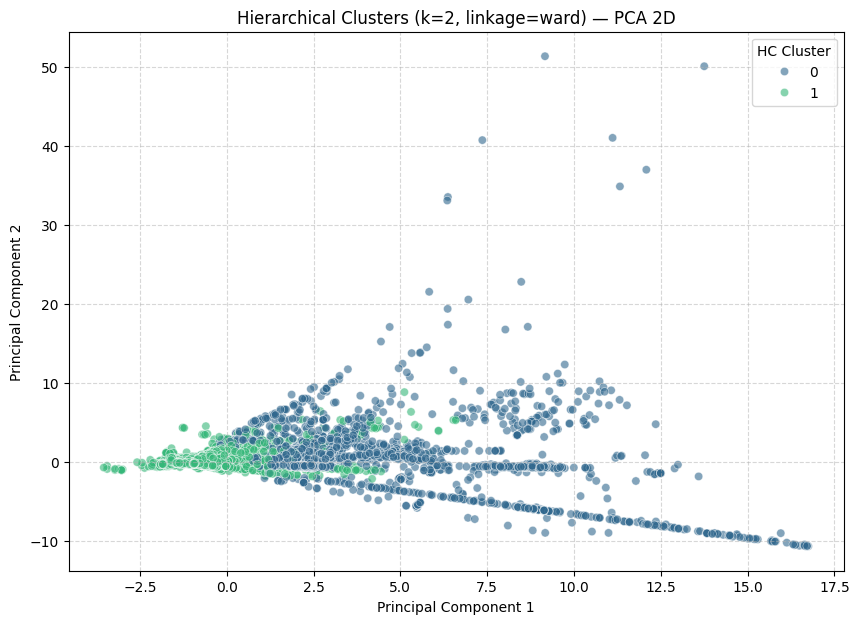

In [32]:
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

# No need to re-fit — hc_best_labels is already computed above
# Just reduce dimensions for plotting
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)         # ← was X_sample_scaled

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df['HC_Cluster'],
    palette='viridis',
    alpha=0.6
)
plt.title(f'Hierarchical Clusters (k={best_k}, linkage={best_linkage}) — PCA 2D')  # ← dynamic title
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='HC Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [33]:
hc_analysis = pd.crosstab(
    index=df['Label_Name'],           # ← was df_sample['Label_Name']
    columns=df['HC_Cluster'],         # ← was df_sample['HC_Cluster']
    margins=True
)

print("Hierarchical Cluster Distribution vs. True Label Names:")   # ← removed "(Sample Data)"
display(hc_analysis)

Hierarchical Cluster Distribution vs. True Label Names:


HC_Cluster,0,1,All
Label_Name,,,
BENIGN,2030,14709,16739
Bot,0,16,16
DDoS,167,857,1024
DoS GoldenEye,22,60,82
DoS Hulk,1068,313,1381
DoS Slowhttptest,29,13,42
DoS slowloris,27,16,43
FTP-Patator,0,47,47
Heartbleed,7,0,7


## DBScan

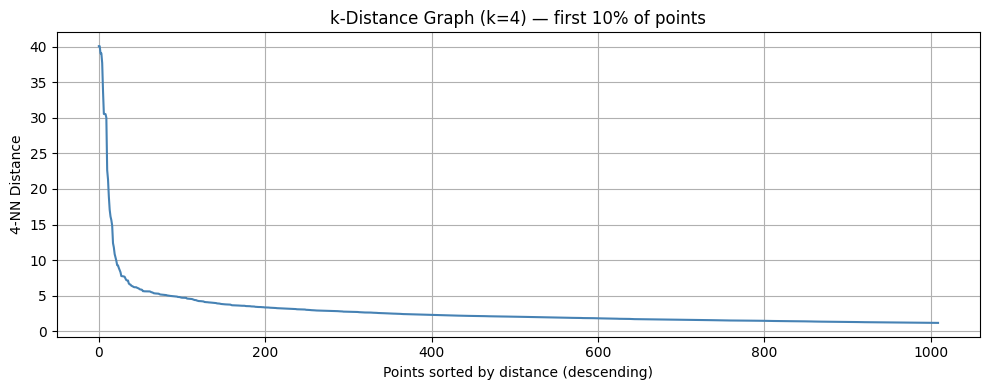

   eps | min_samp | n_clusters |  noise_% |  Silhouette |  Davies-Bouldin
------------------------------------------------------------------------
  50.0 |        5 |          1 |     0.0% |         N/A |             N/A


In [ ]:
# =============================================================
# DBSCAN CLUSTERING
# =============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.decomposition import PCA
from itertools import product

# -------------------------------------------------------------
# Step 1: k-distance plot to estimate a good epsilon
# -------------------------------------------------------------
# Use k = min_samples - 1 (commonly 4) for the k-NN distance plot
k_nn = 4
nbrs = NearestNeighbors(n_neighbors=k_nn).fit(X_scaled)
distances, _ = nbrs.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])[::-1]

# Only plot the first 10% of points — elbow always appears here
cutoff = int(len(k_distances) * 0.05)

plt.figure(figsize=(10, 4))
plt.plot(k_distances[:cutoff], color='steelblue')
plt.title(f'k-Distance Graph (k={k_nn}) — first 10% of points')
plt.xlabel('Points sorted by distance (descending)')
plt.ylabel(f'{k_nn}-NN Distance')
plt.grid(True)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# Step 2: Grid search over (eps, min_samples)
# -------------------------------------------------------------
eps_values        = [0.3, 0.5, 0.8, 1.0, 1.5, 2.0]
min_samples_values = [5, 10, 20, 50]

results = []

print(f"{'eps':>6} | {'min_samp':>8} | {'n_clusters':>10} | {'noise_%':>8} | {'Silhouette':>11} | {'Davies-Bouldin':>15}")
print("-" * 72)

for eps, min_samp in product(eps_values, min_samples_values):
    db = DBSCAN(eps=eps, min_samples=min_samp, n_jobs=-1)
    labels = db.fit_predict(X_scaled)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_pct  = np.sum(labels == -1) / len(labels) * 100

    # Need at least 2 clusters and some non-noise points to score
    non_noise_mask = labels != -1
    if n_clusters >= 2 and non_noise_mask.sum() > 0:
        sil = silhouette_score(X_scaled[non_noise_mask], labels[non_noise_mask])
        dbi = davies_bouldin_score(X_scaled[non_noise_mask], labels[non_noise_mask])
    else:
        sil, dbi = np.nan, np.nan

    results.append({
        'eps': eps, 'min_samples': min_samp,
        'n_clusters': n_clusters, 'noise_pct': noise_pct,
        'silhouette': sil, 'davies_bouldin': dbi
    })
    print(f"{eps:>6.1f} | {min_samp:>8} | {n_clusters:>10} | {noise_pct:>7.1f}% | "
          f"{sil if not np.isnan(sil) else 'N/A':>11} | "
          f"{dbi if not np.isnan(dbi) else 'N/A':>15}")

# -------------------------------------------------------------
# Step 3: Pick best config (highest Silhouette, noise < 30%)
# -------------------------------------------------------------
valid = [r for r in results if not np.isnan(r['silhouette']) and r['noise_pct'] < 30]
best  = max(valid, key=lambda r: r['silhouette'])

print(f"\n  Best configuration:")
print(f"   eps          : {best['eps']}")
print(f"   min_samples  : {best['min_samples']}")
print(f"   n_clusters   : {best['n_clusters']}")
print(f"   Noise points : {best['noise_pct']:.1f}%")
print(f"   Silhouette   : {best['silhouette']:.4f}")
print(f"   Davies-Bouldin: {best['davies_bouldin']:.4f}")

# -------------------------------------------------------------
# Step 4: Final DBSCAN model with best params
# -------------------------------------------------------------
db_best = DBSCAN(eps=best['eps'], min_samples=best['min_samples'], n_jobs=-1)
dbscan_labels = db_best.fit_predict(X_scaled)
df['DBSCAN_Cluster'] = dbscan_labels

# -------------------------------------------------------------
# Step 5: Evaluation vs Ground Truth
# -------------------------------------------------------------
# Exclude noise points for ARI/NMI (noise label = -1)
non_noise = dbscan_labels != -1
ari = adjusted_rand_score(y[non_noise], dbscan_labels[non_noise])
nmi = normalized_mutual_info_score(y[non_noise], dbscan_labels[non_noise])

print(f"\n   ARI  : {ari:.4f}  (1.0 = perfect, 0 = random)")
print(f"   NMI  : {nmi:.4f}  (1.0 = perfect, 0 = no mutual info)")

# -------------------------------------------------------------
# Step 6: Visualisation with PCA (2D)
# -------------------------------------------------------------
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# — DBSCAN clusters
unique_labels = sorted(set(dbscan_labels))
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_labels)))

for lbl, col in zip(unique_labels, colors):
    mask = dbscan_labels == lbl
    label_str = f'Noise ({mask.sum()})' if lbl == -1 else f'Cluster {lbl} ({mask.sum()})'
    marker = 'x' if lbl == -1 else 'o'
    alpha  = 0.3 if lbl == -1 else 0.6
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1],
                    c=[col], label=label_str, marker=marker,
                    s=10, alpha=alpha)

axes[0].set_title(f'DBSCAN Clusters (ε={best["eps"]}, min_samples={best["min_samples"]})')
axes[0].set_xlabel('PC 1')
axes[0].set_ylabel('PC 2')
axes[0].legend(loc='upper right', fontsize=7, markerscale=2)
axes[0].grid(True)

# — Ground truth labels for comparison
unique_true = sorted(set(y))
colors_gt   = plt.cm.tab10(np.linspace(0, 1, len(unique_true)))

for lbl, col in zip(unique_true, colors_gt):
    mask = np.array(y) == lbl
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1],
                    c=[col], label=str(lbl), s=10, alpha=0.5)

axes[1].set_title('Ground Truth Labels (for comparison)')
axes[1].set_xlabel('PC 1')
axes[1].set_ylabel('PC 2')
axes[1].legend(loc='upper right', fontsize=7, markerscale=2)
axes[1].grid(True)

plt.suptitle('DBSCAN — PCA 2D Projection', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n DBSCAN complete. Cluster labels saved to df.")